Yi-Ning Li
DSCI 552 HW 6

### 1. Tree-based methods

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

#### a. load dataset

In [2]:
trainPath = '../data/aps_failure_training_set.csv'
testPath = '../data/aps_failure_test_set.csv'
trainData = pd.read_csv(trainPath, skiprows=20, na_values='na')
testData = pd.read_csv(testPath, skiprows=20, na_values='na')

#### b. data preparation
##### i. 
Data imputation techniques for handling missing values:
- deletion: removing rows or columns containing missing values
- mean imputation: replacing missing values with mean of each feature
- median imputation: replacing missing values with median of each feature
- KNN imputation: estimating missing values using similar observations
- iterative imputation: predicting missing values using other features

We will use median imputation to apply to the data. 

In [3]:
missingCounts = trainData.isna().sum()
print('Total Missing Values:', missingCounts.sum())
print('Features with Missing Values:', (missingCounts > 0).sum())
display(missingCounts[missingCounts > 0].sort_values(ascending=False).head(10))
featureNames = trainData.columns.drop('class')
imputer = SimpleImputer(strategy='median')
trainFeatures = pd.DataFrame(imputer.fit_transform(trainData[featureNames]), columns=featureNames, index=trainData.index)
testFeatures = pd.DataFrame(imputer.transform(testData[featureNames]),columns=featureNames,index=testData.index)
trainLabels = trainData['class']
testLabels = testData['class']
print('Training Missing Values:', trainFeatures.isna().sum().sum())
print('Test Missing Values:', testFeatures.isna().sum().sum())
print('Training Features Shape:', trainFeatures.shape)
print('Test Features Shape:', testFeatures.shape)

Total Missing Values: 850015
Features with Missing Values: 169


br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
cr_000    46329
ab_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034
dtype: int64

Training Missing Values: 0
Test Missing Values: 0
Training Features Shape: (60000, 170)
Test Features Shape: (16000, 170)


##### ii. 

In [4]:
featureMeans = trainFeatures.mean()
featureStds = trainFeatures.std(ddof=1)
coeffVariation = featureStds / featureMeans.replace(0, np.nan)
cvResults = pd.DataFrame({'Mean': featureMeans,'Std': featureStds,'CV': coeffVariation})
display(cvResults[['CV']].T.round(3))
print('Number of Features:', len(cvResults))

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
CV,2.451,10.383,2.31,244.323,24.2,19.471,92.918,35.249,17.566,8.647,...,2.594,2.573,2.622,2.847,3.219,5.013,3.259,5.692,49.367,42.482


Number of Features: 170


##### iii. 

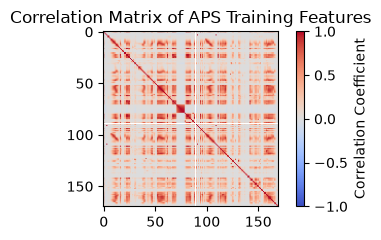

In [5]:
correlationMatrix = trainFeatures.corr()
plt.figure(figsize=(4, 2.5))
plt.imshow(correlationMatrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation Coefficient')
plt.title('Correlation Matrix of APS Training Features')
plt.tight_layout()
plt.show()

##### iv. 

Number of Selected Features: 13


,cf_000,co_000,ad_000,cs_009,dh_000,dj_000,ag_000,as_000,ay_009,ak_000,az_009,ch_000,au_000
Mean,1.431075e+05,1.433300e+05,1.434383e+05,770.509700,4392.640833,37.271333,219.157733,125.407900,1149.619633,907.660700,41.602933,0.000333,228.163133
Std,3.504525e+07,3.504525e+07,3.504525e+07,183327.799564,541244.059962,4379.166430,20363.644580,10952.185372,97411.564901,72998.589477,3238.311769,0.025818,15716.504289
CV,2.448875e+02,2.445074e+02,2.443228e+02,237.930554,123.216097,117.494225,92.917755,87.332500,84.733735,80.424975,77.838544,77.453857,68.882751


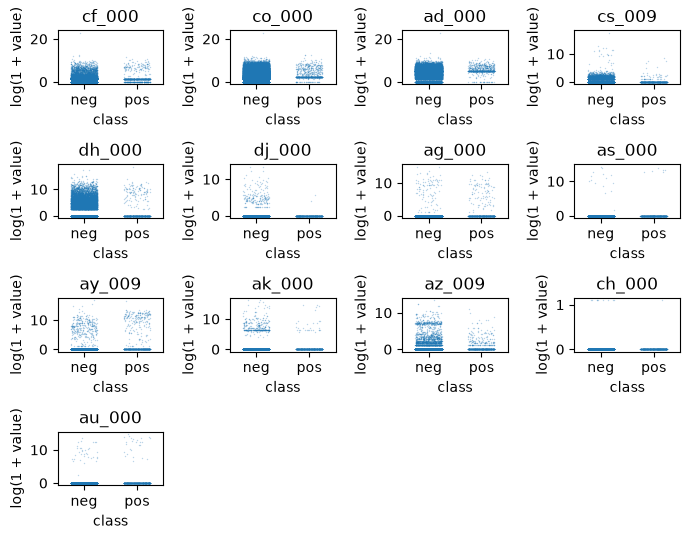

In [6]:
numFeatures = int(np.sqrt(170))
topFeatures = cvResults['CV'].nlargest(numFeatures).index.tolist()
print('Number of Selected Features:', numFeatures)
display(cvResults.loc[topFeatures].sort_values('CV', ascending=False).T)
plotData = trainFeatures[topFeatures].copy()
plotData['class'] = trainLabels.values
fig, axes = plt.subplots(4, 4, figsize=(7, 5.5))
axes = axes.flatten()
for i, feature in enumerate(topFeatures):
    sns.stripplot(data=plotData,x='class',y=np.log1p(plotData[feature]),ax=axes[i],jitter=0.25,size=1,alpha=0.3)
    axes[i].set_title(feature)
    axes[i].set_ylabel('log(1 + value)')
for i in range(len(topFeatures), len(axes)):
    axes[i].axis('off')
plt.tight_layout()
plt.show()

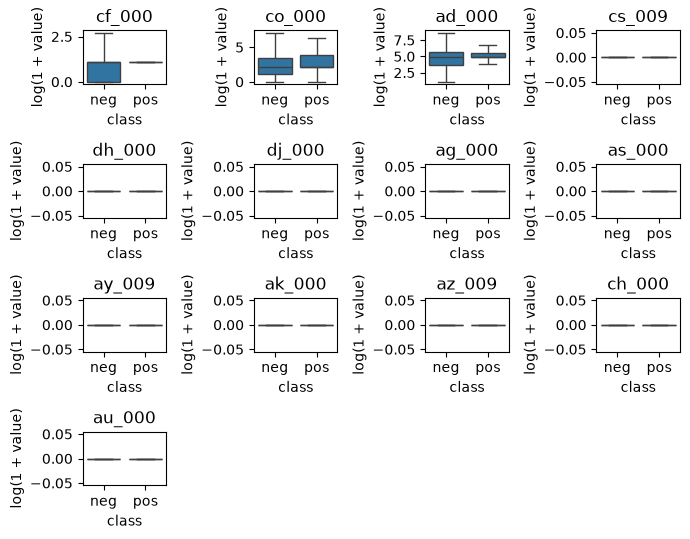

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(7, 5.5))
axes = axes.flatten()
for i, feature in enumerate(topFeatures):
    sns.boxplot(x=plotData['class'],y=np.log1p(plotData[feature]),ax=axes[i],showfliers=False)
    axes[i].set_title(feature)
    axes[i].set_ylabel('log(1 + value)')
for i in range(len(topFeatures), len(axes)):
    axes[i].axis('off')
plt.tight_layout()
plt.show()

13 features with highest coefficients of variation were selected for visualization. log(1+x) transformation was applied to both scatter and box plots for readability purposes. The plots show highly skewed distributions, and many observations were concentrated near zero. Some features like co_000 and ad_000 exhibit differences between the positive and negative classes, but there is still substantial overlap. Cannot draw conclusions about significance of these feaatures from scatter plots alone because while a high CV indicates high relative variability, it does not mean strong predictive power. Therefore, more statistical analysis and modeling is needed. 

##### v. 

In [8]:
classCounts = trainLabels.value_counts()
classPercentages = trainLabels.value_counts(normalize=True) * 100
classDistribution = pd.DataFrame({'Count': classCounts,'Percentage (%)': classPercentages})
display(classDistribution)

,Count,Percentage (%)
class,,
neg,59000,98.333333
pos,1000,1.666667


This data set is imbalanced, with 59000 negative observations (98.33%) and 1000 positive observations (1.67%). There is a negative-to-positive ratio of 59:1. 

#### c. random forest

In [9]:
randomForestModel = RandomForestClassifier(n_estimators=100,oob_score=True,random_state=1,n_jobs=-1)
randomForestModel.fit(trainFeatures, trainLabels);

In [10]:
trainPredictions = randomForestModel.predict(trainFeatures)
testPredictions = randomForestModel.predict(testFeatures)
positiveIndex = list(randomForestModel.classes_).index('pos')
trainProbabilities = randomForestModel.predict_proba(trainFeatures)[:, positiveIndex]
testProbabilities = randomForestModel.predict_proba(testFeatures)[:, positiveIndex]
trainConfusionMatrix = confusion_matrix(trainLabels, trainPredictions, labels=['neg', 'pos'])
testConfusionMatrix = confusion_matrix(testLabels, testPredictions, labels=['neg', 'pos'])
trainError = 1 - accuracy_score(trainLabels, trainPredictions)
testError = 1 - accuracy_score(testLabels, testPredictions)
oobError = 1 - randomForestModel.oob_score_
trainAuc = roc_auc_score((trainLabels == 'pos').astype(int), trainProbabilities)
testAuc = roc_auc_score((testLabels == 'pos').astype(int), testProbabilities)
print('Training Confusion Matrix:')
print(trainConfusionMatrix)
print('\nTest Confusion Matrix:')
print(testConfusionMatrix)
print(f'\nTraining Misclassification Error: {trainError:.4f}')
print(f'Test Misclassification Error: {testError:.4f}')
print(f'OOB Error: {oobError:.4f}')
print(f'Training AUC: {trainAuc:.4f}')
print(f'Test AUC: {testAuc:.4f}')

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]

Test Confusion Matrix:
[[15610    15]
 [  109   266]]

Training Misclassification Error: 0.0000
Test Misclassification Error: 0.0078
OOB Error: 0.0061
Training AUC: 1.0000
Test AUC: 0.9944


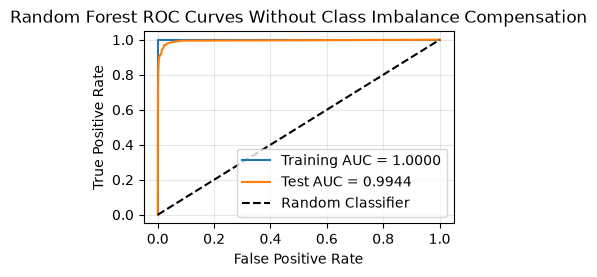

OOB Error: 0.0061
Test Error: 0.0078
Difference: 0.0016


In [11]:
trainFpr, trainTpr, _ = roc_curve((trainLabels == 'pos').astype(int), trainProbabilities)
testFpr, testTpr, _ = roc_curve((testLabels == 'pos').astype(int), testProbabilities)
plt.figure(figsize=(4, 2.5))
plt.plot(trainFpr, trainTpr, label=f'Training AUC = {trainAuc:.4f}')
plt.plot(testFpr, testTpr, label=f'Test AUC = {testAuc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curves Without Class Imbalance Compensation')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f'OOB Error: {oobError:.4f}')
print(f'Test Error: {testError:.4f}')
print(f'Difference: {abs(oobError - testError):.4f}')

Random forest clasifier without class imbalance compensation had a training misclassification error of 0% and test misclassification error of 0.78%. It had AUC values of 1.0000 for training and 0.9944 for test. The high AUC values indicate strong classification performance, but the perfect training performance could suggest possible overfitting. 

Even though there was a low test error, the model misclassified 109 positive observations as negative, which indicates it had difficulty identifying some minority-class instances. The OOB error of 0.61% is close to the test error of 0.78%, with a difference of 0.16 percentage points. This suggests that OOB estimation provides a reasonable approximation of generalization error. 

#### d. random forest with class imbalance
Class imbalance in random forests can be addressed with class weighting, oversampling the minority class, or undersampling the majority class. Class weighting assigns greater importance to minority-class observations during training. For this model, class_weight='balanced_subsample' was used to automatically assign weights inversely proportional to class frequencies within each tree's bootstrap sample. This will compensate for class imbalance without modifying the original training dataset. 

In [12]:
balancedForestModel = RandomForestClassifier(n_estimators=100,class_weight='balanced_subsample',oob_score=True,random_state=1,n_jobs=-1)
balancedForestModel.fit(trainFeatures, trainLabels)
print('OOB Score:', balancedForestModel.oob_score_)
print('Missing OOB Predictions:',(balancedForestModel.oob_decision_function_.sum(axis=1) == 0).sum())

OOB Score: 0.9921333333333333
Missing OOB Predictions: 0


In [13]:
balancedTrainPredictions = balancedForestModel.predict(trainFeatures)
balancedTestPredictions = balancedForestModel.predict(testFeatures)
positiveIndex = list(balancedForestModel.classes_).index('pos')
balancedTrainProbabilities = balancedForestModel.predict_proba(trainFeatures)[:, positiveIndex]
balancedTestProbabilities = balancedForestModel.predict_proba(testFeatures)[:, positiveIndex]
balancedTrainConfusionMatrix = confusion_matrix(trainLabels, balancedTrainPredictions, labels=['neg', 'pos'])
balancedTestConfusionMatrix = confusion_matrix(testLabels, balancedTestPredictions, labels=['neg', 'pos'])
balancedTrainError = 1 - accuracy_score(trainLabels, balancedTrainPredictions)
balancedTestError = 1 - accuracy_score(testLabels, balancedTestPredictions)
balancedOobError = 1 - balancedForestModel.oob_score_
balancedTrainAuc = roc_auc_score((trainLabels == 'pos').astype(int),balancedTrainProbabilities)
balancedTestAuc = roc_auc_score((testLabels == 'pos').astype(int),balancedTestProbabilities)
print('Training Confusion Matrix:')
print(balancedTrainConfusionMatrix)
print('\nTest Confusion Matrix:')
print(balancedTestConfusionMatrix)
print(f'\nTraining Misclassification Error: {balancedTrainError:.4f}')
print(f'Test Misclassification Error: {balancedTestError:.4f}')
print(f'OOB Error: {balancedOobError:.4f}')
print(f'Training AUC: {balancedTrainAuc:.4f}')
print(f'Test AUC: {balancedTestAuc:.4f}')

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]

Test Confusion Matrix:
[[15612    13]
 [  153   222]]

Training Misclassification Error: 0.0000
Test Misclassification Error: 0.0104
OOB Error: 0.0079
Training AUC: 1.0000
Test AUC: 0.9909


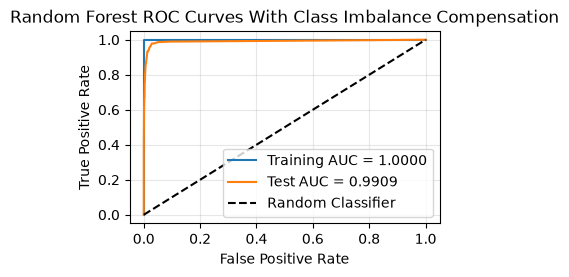

In [14]:
balancedTrainFpr, balancedTrainTpr, _ = roc_curve((trainLabels == 'pos').astype(int),balancedTrainProbabilities)
balancedTestFpr, balancedTestTpr, _ = roc_curve((testLabels == 'pos').astype(int),balancedTestProbabilities)
plt.figure(figsize=(4, 2.5))
plt.plot(balancedTrainFpr, balancedTrainTpr,label=f'Training AUC = {balancedTrainAuc:.4f}')
plt.plot(balancedTestFpr, balancedTestTpr,label=f'Test AUC = {balancedTestAuc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curves With Class Imbalance Compensation')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
comparisonResults = pd.DataFrame({'Metric': ['Training Error','Test Error','OOB Error','Training AUC','Test AUC'],'Unbalanced RF': [trainError,testError,oobError,trainAuc,testAuc],'Balanced RF': [balancedTrainError,balancedTestError,balancedOobError,balancedTrainAuc,balancedTestAuc]})
display(comparisonResults.round(4))

,Metric,Unbalanced RF,Balanced RF
0,Training Error,0.0000,0.0000
1,Test Error,0.0078,0.0104
2,OOB Error,0.0061,0.0079
3,Training AUC,1.0000,1.0000
4,Test AUC,0.9944,0.9909


Balanced random forest had a higher test misclassification (1.04% vs 0.78%) and lower AUC (0.9909 vs 0.9944) compared to unbalanced. OOB also increased from 0.61% to 0.79% from unbalanced to balanced. Furthermore, number of false negatives increased from 109 to 153, indicating that class imbalance compensation did not improve minority-class detection. 

#### e.  XGBoost and Model Trees

In [16]:
xgbTrainFeatures = trainData[featureNames]
xgbTestFeatures = testData[featureNames]
xgbTrainLabels = (trainLabels == 'pos').astype(int)
xgbTestLabels = (testLabels == 'pos').astype(int)
print('Training Features Shape:', xgbTrainFeatures.shape)
print('Test Features Shape:', xgbTestFeatures.shape)
print('Training Class Distribution:')
print(xgbTrainLabels.value_counts())

Training Features Shape: (60000, 170)
Test Features Shape: (16000, 170)
Training Class Distribution:
class
0    59000
1     1000
Name: count, dtype: int64


In [17]:
crossValidation = StratifiedKFold(n_splits=5,shuffle=True,random_state=1)
xgbPipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('model', XGBClassifier(n_estimators=100,max_depth=6,learning_rate=0.1,objective='binary:logistic',tree_method='hist',reg_lambda=1,scale_pos_weight=1,random_state=1,n_jobs=-1,eval_metric='logloss'))])
alphaGrid = {'model__reg_alpha': [0, 0.1, 1, 10]}
xgbGridSearch = GridSearchCV(estimator=xgbPipeline,param_grid=alphaGrid,scoring={'auc': 'roc_auc','accuracy': 'accuracy'},refit='auc',cv=crossValidation,n_jobs=1,verbose=1)

In [18]:
xgbGridSearch.fit(xgbTrainFeatures, xgbTrainLabels)
bestAlpha = xgbGridSearch.best_params_['model__reg_alpha']
xgbModel = xgbGridSearch.best_estimator_
print('Best Alpha:', bestAlpha)
print(f'Best Cross-Validation AUC: {xgbGridSearch.best_score_:.4f}')
cvResultsXgb = pd.DataFrame(xgbGridSearch.cv_results_)
alphaResults = cvResultsXgb[['param_model__reg_alpha','mean_test_auc','mean_test_accuracy']].copy()
alphaResults.columns = ['Alpha','CV AUC','CV Accuracy']
alphaResults['CV Error'] = 1 - alphaResults['CV Accuracy']
display(alphaResults)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Alpha: 10
Best Cross-Validation AUC: 0.9893


,Alpha,CV AUC,CV Accuracy,CV Error
0,0.0,0.988459,0.993983,0.006017
1,0.1,0.988656,0.993817,0.006183
2,1.0,0.988830,0.994017,0.005983
3,10.0,0.989291,0.992717,0.007283


In [19]:
xgbTrainPredictions = xgbModel.predict(xgbTrainFeatures)
xgbTestPredictions = xgbModel.predict(xgbTestFeatures)
xgbTrainProbabilities = xgbModel.predict_proba(xgbTrainFeatures)[:, 1]
xgbTestProbabilities = xgbModel.predict_proba(xgbTestFeatures)[:, 1]
xgbTrainConfusionMatrix = confusion_matrix(xgbTrainLabels, xgbTrainPredictions)
xgbTestConfusionMatrix = confusion_matrix(xgbTestLabels, xgbTestPredictions)
xgbTrainError = 1 - accuracy_score(xgbTrainLabels, xgbTrainPredictions)
xgbTestError = 1 - accuracy_score(xgbTestLabels, xgbTestPredictions)
xgbTrainAuc = roc_auc_score(xgbTrainLabels, xgbTrainProbabilities)
xgbTestAuc = roc_auc_score(xgbTestLabels, xgbTestProbabilities)
bestCvError = 1 - xgbGridSearch.cv_results_['mean_test_accuracy'][xgbGridSearch.best_index_]
print('Training Confusion Matrix:')
print(xgbTrainConfusionMatrix)
print('\nTest Confusion Matrix:')
print(xgbTestConfusionMatrix)
print(f'\nTraining Misclassification Error: {xgbTrainError:.4f}')
print(f'Test Misclassification Error: {xgbTestError:.4f}')
print(f'Cross-Validation Error: {bestCvError:.4f}')
print(f'Training AUC: {xgbTrainAuc:.4f}')
print(f'Test AUC: {xgbTestAuc:.4f}')

Training Confusion Matrix:
[[58974    26]
 [  148   852]]

Test Confusion Matrix:
[[15602    23]
 [  104   271]]

Training Misclassification Error: 0.0029
Test Misclassification Error: 0.0079
Cross-Validation Error: 0.0073
Training AUC: 0.9979
Test AUC: 0.9959


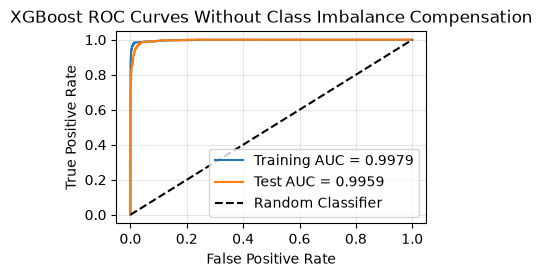

In [20]:
xgbTrainFpr, xgbTrainTpr, _ = roc_curve(xgbTrainLabels, xgbTrainProbabilities)
xgbTestFpr, xgbTestTpr, _ = roc_curve(xgbTestLabels, xgbTestProbabilities)
plt.figure(figsize=(4, 2.5))
plt.plot(xgbTrainFpr, xgbTrainTpr,label=f'Training AUC = {xgbTrainAuc:.4f}')
plt.plot(xgbTestFpr, xgbTestTpr,label=f'Test AUC = {xgbTestAuc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curves Without Class Imbalance Compensation')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
print(f'Cross-Validation Error: {bestCvError:.4f}')
print(f'Test Error: {xgbTestError:.4f}')
print(f'Difference: {abs(bestCvError - xgbTestError):.4f}')

Cross-Validation Error: 0.0073
Test Error: 0.0079
Difference: 0.0007


Using 5-fold stratified cross-validation, optimal alpha was determined to be 10 based on the highest cross-validation AUC of 0.9893. The XGBoost model achieved a training misclassification error of 0.29% and a test misclassification error of 0.79%, with AUC values of 0.9979 and 0.9959, respectively.

The test confusion matrix shows 104 false negatives and 23 false positives, indicating that some minority-class observations were misclassified despite the high AUC. The cross-validation error was 0.73%, which is close to the test error of 0.79%. This suggests that cross-validation provides a reasonable estimate of generalization performance.

#### f. SMOTE

In [22]:
smotePipeline = ImbPipeline([('imputer', SimpleImputer(strategy='median')),('smote', SMOTE(random_state=1)),('model', XGBClassifier(n_estimators=100,max_depth=6,learning_rate=0.1,objective='binary:logistic',tree_method='hist',reg_lambda=1,scale_pos_weight=1,random_state=1,n_jobs=-1,eval_metric='logloss'))])
smoteAlphaGrid = {'model__reg_alpha': [0, 0.1, 1, 10]}

In [23]:
smoteGridSearch = GridSearchCV(estimator=smotePipeline,param_grid=smoteAlphaGrid,scoring={'auc': 'roc_auc','accuracy': 'accuracy'},refit='auc',cv=crossValidation,n_jobs=1,verbose=1)

In [24]:
smoteGridSearch.fit(xgbTrainFeatures, xgbTrainLabels)
smoteBestAlpha = smoteGridSearch.best_params_['model__reg_alpha']
smoteModel = smoteGridSearch.best_estimator_
print('Best Alpha:', smoteBestAlpha)
print(f'Best Cross-Validation AUC: {smoteGridSearch.best_score_:.4f}')
smoteCvResults = pd.DataFrame(smoteGridSearch.cv_results_)
smoteAlphaResults = smoteCvResults[['param_model__reg_alpha','mean_test_auc','mean_test_accuracy']].copy()
smoteAlphaResults.columns = ['Alpha','CV AUC','CV Accuracy']
smoteAlphaResults['CV Error'] = 1 - smoteAlphaResults['CV Accuracy']
display(smoteAlphaResults)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Alpha: 10
Best Cross-Validation AUC: 0.9873


,Alpha,CV AUC,CV Accuracy,CV Error
0,0.0,0.986258,0.990133,0.009867
1,0.1,0.987218,0.989967,0.010033
2,1.0,0.986637,0.990033,0.009967
3,10.0,0.987350,0.989167,0.010833


In [25]:
smoteTrainPredictions = smoteModel.predict(xgbTrainFeatures)
smoteTestPredictions = smoteModel.predict(xgbTestFeatures)
smoteTrainProbabilities = smoteModel.predict_proba(xgbTrainFeatures)[:, 1]
smoteTestProbabilities = smoteModel.predict_proba(xgbTestFeatures)[:, 1]
smoteTrainConfusionMatrix = confusion_matrix(xgbTrainLabels, smoteTrainPredictions)
smoteTestConfusionMatrix = confusion_matrix(xgbTestLabels, smoteTestPredictions)
smoteTrainError = 1 - accuracy_score(xgbTrainLabels, smoteTrainPredictions)
smoteTestError = 1 - accuracy_score(xgbTestLabels, smoteTestPredictions)
smoteTrainAuc = roc_auc_score(xgbTrainLabels, smoteTrainProbabilities)
smoteTestAuc = roc_auc_score(xgbTestLabels, smoteTestProbabilities)
smoteCvError = 1 - smoteGridSearch.cv_results_['mean_test_accuracy'][smoteGridSearch.best_index_]
print('Training Confusion Matrix:')
print(smoteTrainConfusionMatrix)
print('\nTest Confusion Matrix:')
print(smoteTestConfusionMatrix)
print(f'\nTraining Misclassification Error: {smoteTrainError:.4f}')
print(f'Test Misclassification Error: {smoteTestError:.4f}')
print(f'Cross-Validation Error: {smoteCvError:.4f}')
print(f'Training AUC: {smoteTrainAuc:.4f}')
print(f'Test AUC: {smoteTestAuc:.4f}')

Training Confusion Matrix:
[[58659   341]
 [   45   955]]

Test Confusion Matrix:
[[15509   116]
 [   45   330]]

Training Misclassification Error: 0.0064
Test Misclassification Error: 0.0101
Cross-Validation Error: 0.0108
Training AUC: 0.9986
Test AUC: 0.9949


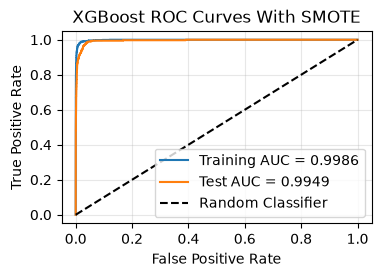

In [26]:
smoteTrainFpr, smoteTrainTpr, _ = roc_curve(xgbTrainLabels, smoteTrainProbabilities)
smoteTestFpr, smoteTestTpr, _ = roc_curve(xgbTestLabels, smoteTestProbabilities)
plt.figure(figsize=(4, 2.5))
plt.plot(smoteTrainFpr, smoteTrainTpr,label=f'Training AUC = {smoteTrainAuc:.4f}')
plt.plot(smoteTestFpr, smoteTestTpr,label=f'Test AUC = {smoteTestAuc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curves With SMOTE')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
xgbComparison = pd.DataFrame({'Metric': ['Training Error','Test Error','CV Error','Training AUC','Test AUC','Test False Positives','Test False Negatives'],'Without SMOTE': [xgbTrainError,xgbTestError,bestCvError,xgbTrainAuc,xgbTestAuc,xgbTestConfusionMatrix[0, 1],xgbTestConfusionMatrix[1, 0]],'With SMOTE': [smoteTrainError,smoteTestError,smoteCvError,smoteTrainAuc,smoteTestAuc,smoteTestConfusionMatrix[0, 1],smoteTestConfusionMatrix[1, 0]]})
display(xgbComparison.round(4))

,Metric,Without SMOTE,With SMOTE
0,Training Error,0.0029,0.0064
1,Test Error,0.0079,0.0101
2,CV Error,0.0073,0.0108
3,Training AUC,0.9979,0.9986
4,Test AUC,0.9959,0.9949
5,Test False Positives,23.0000,116.0000
6,Test False Negatives,104.0000,45.0000


Using SMOTE with 5-fold stratified cross-validation, optimal alpha was determined to be 10 based on the highest cross-validation AUC of 0.9873. The model achieved a training misclassification error of 0.64% and a test misclassification error of 1.01%, with AUC values of 0.9986 and 0.9949, respectively. The cross-validation error of 1.08% was close to the test error of 1.01%.

Compared to XGBoost without SMOTE, test misclassification error increased from 0.79% to 1.01%, and test AUC decreased slightly from 0.9959 to 0.9949. However, false negatives decreased from 104 to 45, while false positives increased from 23 to 116. This suggests that SMOTE improved minority-class detection at the expense of more false positives and a slightly higher overall misclassification error.

### 2. ISLR 6.6.3
#### a. As we increase s from 0, the training RSS will: 
iv. steadily decrease. Larger s allows model to fit the training data more closely, reducing RSS. 
#### b. As we increase s from 0, the test RSS will: 
ii. decrease initially, and then eventually start increasing in a U shape. It initially decreases as bias decreases, then increases as variance and overfitting become more significant. 
#### c. As we increase s from 0, the variance will: 
iii. steadily increase. Greater flexibility makes model more sensitive to variations in training data. 
#### d. As we increase s from 0, the squared bias will: 
iv. steadily decrease. Greater flexibility allows model to capture more complex relationships, reducing bias. 
#### e. As we increase s from 0, the irreducible error will: 
v. remain constant. Irreducible error depends on inherent noise, not model flexibility. 

### 3. ISLR, 6.6.5
#### a. 
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(\beta_1^2+\beta_2^2)
\right]
$$

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, and $\hat{\beta}_0=0$, this simplifies to

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(\beta_1^2+\beta_2^2)
\right]
$$
#### b. 
We take the partial derivatives of the ridge regression objective with respect to $\beta_1$ and $\beta_2$:

$$
\frac{\partial L}{\partial \beta_1}
=
-2\sum_{i=1}^{2}x_{i1}
\left(y_i-x_{i1}(\beta_1+\beta_2)\right)
+2\lambda\beta_1=0
$$

$$
\frac{\partial L}{\partial \beta_2}
=
-2\sum_{i=1}^{2}x_{i1}
\left(y_i-x_{i1}(\beta_1+\beta_2)\right)
+2\lambda\beta_2=0
$$

Subtracting the two equations yields

$$
2\lambda\beta_1-2\lambda\beta_2=0
$$

$$
2\lambda(\beta_1-\beta_2)=0
$$

For $\lambda>0$:

$$
\hat{\beta}_1=\hat{\beta}_2
$$

Therefore, ridge regression assigns equal coefficients to the two perfectly correlated predictors.
#### c. 
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(|\beta_1|+|\beta_2|)
\right]
$$

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, this simplifies to

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(|\beta_1|+|\beta_2|)
\right]
$$
#### d. 
Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, the RSS depends only on the sum $\beta_1+\beta_2$.

If we let

$$
c=\hat{\beta}_1+\hat{\beta}_2
$$

any pair of coefficients with the same sum $c$ produces identical predictions and RSS.

By the triangle inequality

$$
|\beta_1|+|\beta_2|
\geq|\beta_1+\beta_2|=|c|
$$

Equality holds when both coefficients have the same sign or one is zero.

For $c>0$, any combination satisfying

$$
\hat{\beta}_1=t,\quad
\hat{\beta}_2=c-t,\quad
0\leq t\leq c
$$

achieves the same minimum objective value.

For $c<0$, the solutions satisfy $c\leq t\leq0$.

Therefore, when the optimal sum $c\neq0$, there are infinitely many optimal coefficient combinations. Lasso coefficients are not necessarily unique because perfectly correlated predictors can still share the same total coefficient in different ways.

### 4. ISLR 8.4.5
Majority vote: Using a threshold of 0.5, 6 trees predict Red and 4 trees predict Green. Therefore, the majority vote classifies the observation as Red.

Average probability: The average predicted probability of Red is:

$$
\bar{P}(\text{Red}\mid X)
=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45
$$

Since 0.45<0.5, the average probability method classifies the observation as Green. 

### 5. ISLR 9.7.3
#### a. 

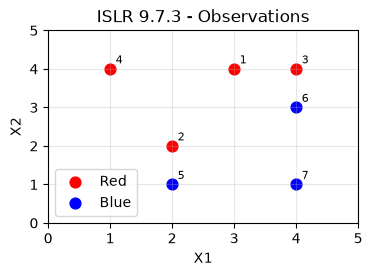

In [28]:
redPoints = np.array([[3, 4],[2, 2],[4, 4],[1, 4]])
bluePoints = np.array([[2, 1],[4, 3],[4, 1]])
def plotQ5Base(titleText):
    plt.figure(figsize=(4, 2.5))
    plt.scatter(redPoints[:, 0], redPoints[:, 1],color='red', label='Red', s=60)
    plt.scatter(bluePoints[:, 0], bluePoints[:, 1],color='blue', label='Blue', s=60)
    for i, point in enumerate(redPoints):
        plt.annotate(str(i + 1), point,xytext=(4, 4), textcoords='offset points', fontsize=8)
    for i, point in enumerate(bluePoints):
        plt.annotate(str(i + 5), point,xytext=(4, 4), textcoords='offset points', fontsize=8)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.title(titleText)
    plt.xlim(0, 5)
    plt.ylim(0, 5)
    plt.xticks(range(6))
    plt.yticks(range(6))
    plt.grid(alpha=0.3)
plotQ5Base('ISLR 9.7.3 - Observations')
plt.legend()
plt.show()

#### b. 

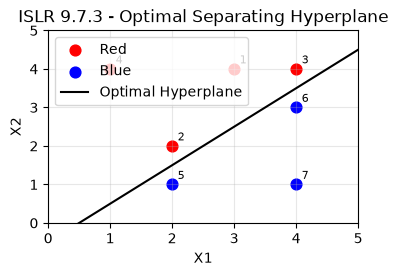

In [29]:
plotQ5Base('ISLR 9.7.3 - Optimal Separating Hyperplane')
xValues = np.linspace(0, 5, 100)
plt.plot(xValues, xValues - 0.5, 'k-', label='Optimal Hyperplane')
plt.legend()
plt.show()

The optimal separating hyperplane is:

$$
X_2=X_1-0.5
$$

Equivalently, in the form $\beta_0+\beta_1X_1+\beta_2X_2=0$

$$
-0.5+X_1-X_2=0
$$

#### c. 
The classification rule is based on the separating hyperplane

$$
0.5-X_1+X_2=0
$$

where $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

Classify an observation as Red if:

$$
0.5-X_1+X_2>0
$$

Otherwise, classify it as Blue.

#### d. 

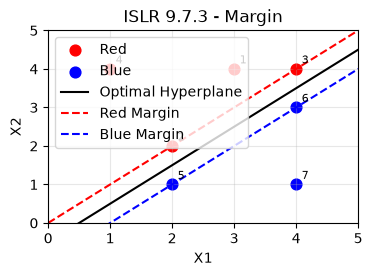

In [30]:
plotQ5Base('ISLR 9.7.3 - Margin')
xValues = np.linspace(0, 5, 100)
plt.plot(xValues, xValues - 0.5, 'k-', label='Optimal Hyperplane')
plt.plot(xValues, xValues, 'r--', label='Red Margin')
plt.plot(xValues, xValues - 1, 'b--', label='Blue Margin')
plt.legend()
plt.show()

#### e. 
The support vectors are:
- Observation 2: Red, $(2,2)$
- Observation 3: Red, $(4,4)$
- Observation 5: Blue, $(2,1)$
- Observation 6: Blue, $(4,3)$

These observations lie directly on the margin boundaries and determine the optimal separating hyperplane.

#### f. 
Observation 7 is not a support vector because it does not lie on the margin boundary. The maximal-margin hyperplane is determined by support vectors (observations 2, 3, 5, and 6). Therefore, a slight movement of observation 7 would not affect the optimal separating hyperplane, as long as it remains outside the margin.

#### g. 

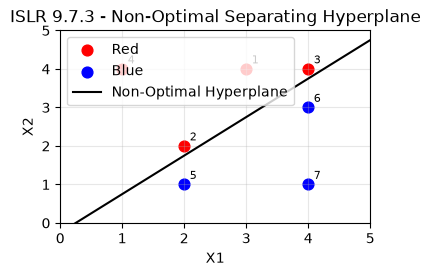

In [31]:
plotQ5Base('ISLR 9.7.3 - Non-Optimal Separating Hyperplane')
xValues = np.linspace(0, 5, 100)
plt.plot(xValues, xValues - 0.25, 'k-', label='Non-Optimal Hyperplane')
plt.legend()
plt.show()

A non-optimal separating hyperplane is

$$
X_2=X_1-0.25
$$

This hyperplane correctly separates the red and blue observations, but does not maximize the margin, since it is closer to the red observations than the optimal hyperplane.

#### h. 

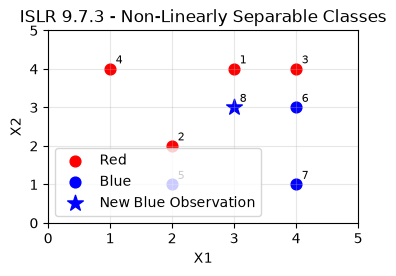

In [32]:
plotQ5Base('ISLR 9.7.3 - Non-Linearly Separable Classes')
plt.scatter(3, 3,color='blue', marker='*', s=140, label='New Blue Observation')
plt.annotate('8', (3, 3),xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.legend()
plt.show()

An additional Blue observation is placed at (3, 3). 